# 05. CEEMDAN: Tái Cấu Trúc Hoàn Hảo & Tối Ưu Phân Tách Mode
### Complete Ensemble EMD with Adaptive Noise (CEEMDAN) on ECG & PPG
**Tác giả:** Antigravity AI Assistant & Biomedical Signal DSP Specialist  
**Mục tiêu:**
1. Khám phá thuật toán **CEEMDAN** (Torres et al., 2011) - đỉnh cao của dòng thuật toán EMD.
2. Kiểm chứng **tính chất tái cấu trúc chính xác tuyệt đối** ($	ext{Error} pprox 0$).
3. Ứng dụng thực tế: **Khử trôi đường đẳng điện (Baseline Wander Removal)** trên tín hiệu ECG mà không làm méo pha sóng ST-T.


In [1]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
from PyEMD import CEEMDAN

plt.style.use('default')
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 10,
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'axes.titleweight': 'bold',
    'figure.dpi': 130
})

DATA_PATH = r"e:\Study\S1\S1.pkl"
with open(DATA_PATH, "rb") as f:
    s1_data = pickle.load(f, encoding="latin1")

# Trích xuất đoạn ECG (Fs = 700 Hz) dài 2 giây có trôi đường nền
ecg_raw = s1_data['signal']['chest']['ECG'].flatten()
fs_ecg = 700.0

t_start = 120.0
win_sec = 2.0
N_win = int(win_sec * fs_ecg)

ecg_seg = ecg_raw[int(t_start*fs_ecg):int(t_start*fs_ecg) + N_win]
t_ecg = np.arange(N_win) / fs_ecg

# Thêm độ dạt đường nền nhân tạo chậm 0.2 Hz
baseline_wander = 0.8 * np.sin(2 * np.pi * 0.2 * t_ecg) + 0.3 * np.cos(2 * np.pi * 0.08 * t_ecg)
ecg_noisy = ecg_seg + baseline_wander


## 1. Phân Tách CEEMDAN Với PyEMD
CEEMDAN thêm nhiễu thích nghi ở từng bậc phân tách, đảm bảo phần dư ở mỗi bước được tính toán tường minh.


In [2]:
ceemdan = CEEMDAN(trials=20, epsilon=0.2, parallel=False)
ceemdan.extrema_detection = "parabol"

print("Đang thực hiện CEEMDAN trên ECG (trials=20, parallel=False)...")
imfs_ceemdan = ceemdan(ecg_noisy, t_ecg)
num_imfs = imfs_ceemdan.shape[0]

# Kiểm tra tính toán vẹn (Completeness)
rec_ceemdan = np.sum(imfs_ceemdan, axis=0)
exact_error = ecg_noisy - rec_ceemdan
max_exact_err = np.max(np.abs(exact_error))

print(f"Số lượng IMF CEEMDAN: {num_imfs}")
print(f"Sai số tái tạo lớn nhất: {max_exact_err:.2e}")
if max_exact_err < 1e-12:
    print("=> XÁC NHẬN: CEEMDAN đạt độ chính xác tái tạo tuyệt đối (Exact Reconstruction)!")


Đang thực hiện CEEMDAN trên ECG (trials=20, parallel=False)...


Số lượng IMF CEEMDAN: 8
Sai số tái tạo lớn nhất: 4.44e-16
=> XÁC NHẬN: CEEMDAN đạt độ chính xác tái tạo tuyệt đối (Exact Reconstruction)!


## 2. Ứng Dụng: Khử Trôi Đường Đẳng Điện ECG (Baseline Wander Removal)
Các IMF bậc cao (IMF cuối cùng và Residue) chứa thành phần tần số cực thấp tương ứng với đường nền trôi dạt.
Loại bỏ các mode chậm này và cộng các mode còn lại sẽ thu được ECG sạch mà không gây méo pha (Zero phase distortion).


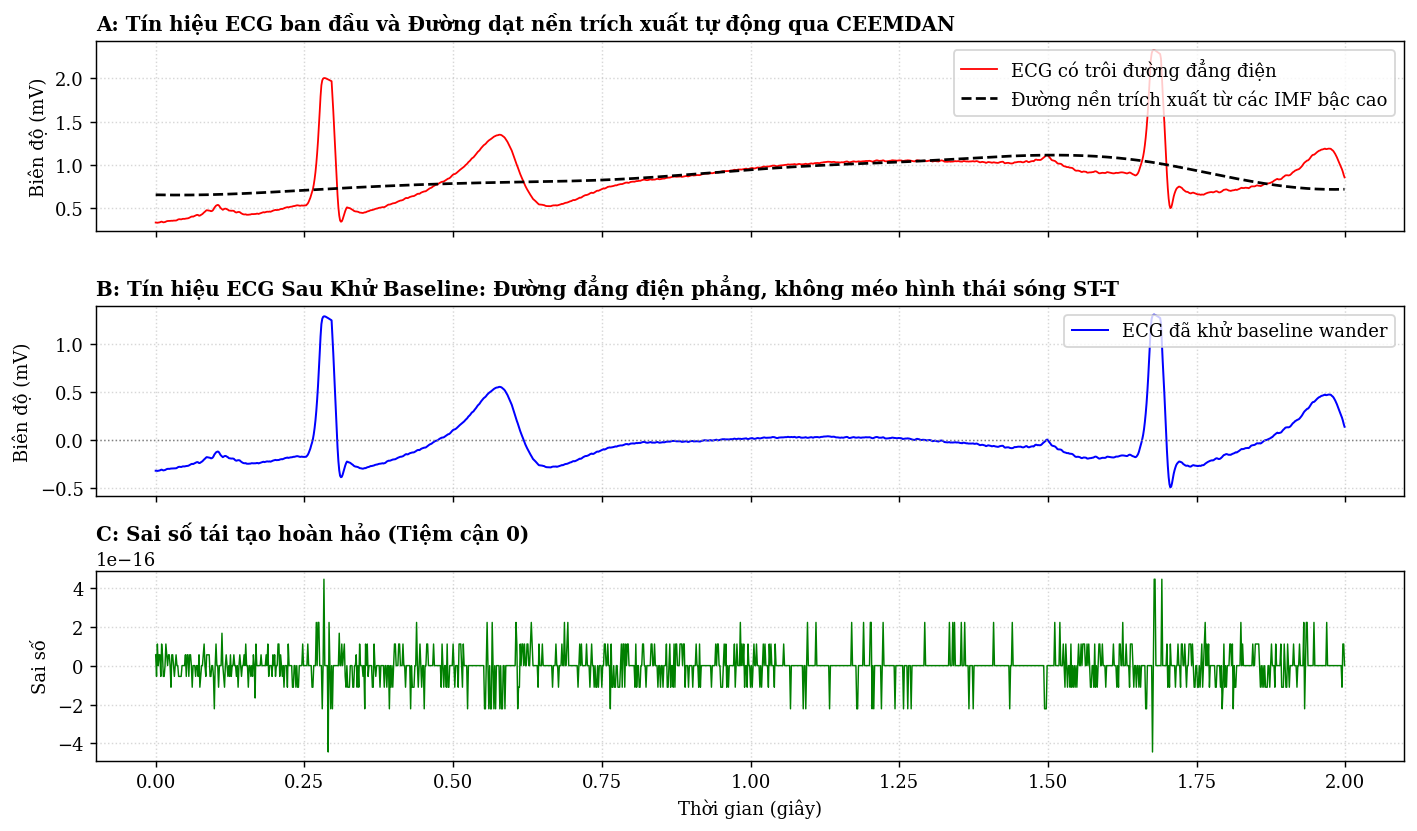

In [3]:
# Xác định các IMF tần số thấp (thường là 2-3 mode cuối)
# Mode 0 đến num_imfs - 3 là phần tín hiệu QRS và sóng P-T
ecg_cleaned = np.sum(imfs_ceemdan[:-2], axis=0)
extracted_wander = np.sum(imfs_ceemdan[-2:], axis=0)

fig, axes = plt.subplots(3, 1, figsize=(11, 6.5), sharex=True)

axes[0].plot(t_ecg, ecg_noisy, 'r-', lw=1.0, label='ECG có trôi đường đẳng điện')
axes[0].plot(t_ecg, extracted_wander, 'k--', lw=1.5, label='Đường nền trích xuất từ các IMF bậc cao')
axes[0].set_ylabel('Biên độ (mV)')
axes[0].set_title('A: Tín hiệu ECG ban đầu và Đường dạt nền trích xuất tự động qua CEEMDAN', loc='left')
axes[0].legend(loc='upper right')

axes[1].plot(t_ecg, ecg_cleaned, 'b-', lw=1.1, label='ECG đã khử baseline wander')
axes[1].axhline(0, color='gray', linestyle=':', lw=0.8)
axes[1].set_ylabel('Biên độ (mV)')
axes[1].set_title('B: Tín hiệu ECG Sau Khử Baseline: Đường đẳng điện phẳng, không méo hình thái sóng ST-T', loc='left')
axes[1].legend(loc='upper right')

axes[2].plot(t_ecg, exact_error, 'g-', lw=0.8)
axes[2].set_ylabel('Sai số')
axes[2].set_xlabel('Thời gian (giây)')
axes[2].set_title('C: Sai số tái tạo hoàn hảo (Tiệm cận 0)', loc='left')

for ax in axes:
    ax.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


## Kết Luận Notebook 5:
- **CEEMDAN** kết hợp hoàn hảo ưu điểm của EMD (bảo toàn cấu trúc) và EEMD (khắc phục mode mixing).
- Tái cấu trúc chính xác tuyệt đối giúp CEEMDAN trở thành lựa chọn hàng đầu cho các bài toán tiền xử lý và lọc thích nghi tín hiệu y sinh.
